#lab 1 EDA:Exploratory Data Analysis

In [ ]:
import os

os.environ['KAGGLE_USERNAME']='heer972005'
os.environ['KAGGLE_KEY']='KGAT_ce74ea23f0412caeb620e23cc1845594'


In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download shivamb/netflix-shows

Dataset URL: https://www.kaggle.com/datasets/shivamb/netflix-shows
License(s): CC0-1.0
netflix-shows.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
#unzipping the file
!unzip -q netflix-shows.zip

replace netflix_titles.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#import the dataset using pandas
df=pd.read_csv("/content/netflix_titles.csv")

In [ ]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [ ]:
df.shape #returns a tuple
#tuples are immutable---so to preserve it

(8807, 12)

In [ ]:
df.info()
#features---gives unquie identity
#even if 1 one of the entries is also mismatched then object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.isnull()
#output is a boolean
#true--null or false

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,False,False,False,False,True,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,False,False
3,False,False,False,True,True,True,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,False,False,False,False,False,False,False,False,False,False,False,False
8803,False,False,False,True,True,True,False,False,False,False,False,False
8804,False,False,False,False,False,False,False,False,False,False,False,False
8805,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()
#returns a dataframe
#return summation of missing value

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
#ml models cannot be trained on empty entries
#dataset charateristics should be maintained

#imputing the missing value---as unknown
df['director']=df['director'].fillna('Unknown')
#na--not available


In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df['cast']=df['cast'].fillna('Unknown')
df['country']=df['country'].fillna('Unknown')
df['date_added']=df['date_added'].fillna('Unknown')
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,4
duration,3


In [ ]:
df['rating'].mode()[0] #output is series

'TV-MA'

In [ ]:
df['rating']=df['rating'].fillna(df['rating'].mode()[0])
df['duration']=df['duration'].fillna(df['duration'].mode()[0])

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

<Axes: xlabel='type', ylabel='count'>

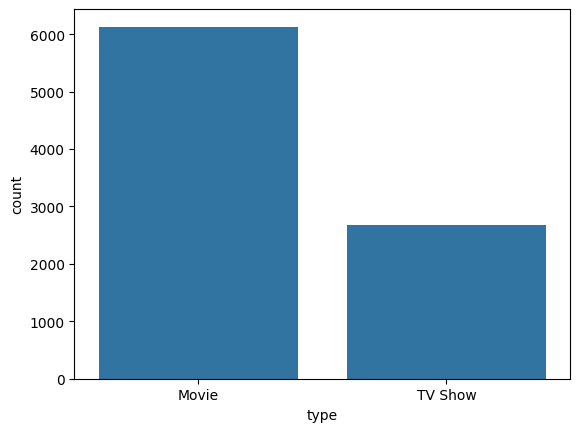

In [ ]:
#data visalisations
sns.countplot(x='type',data=df)

<Axes: ylabel='director'>

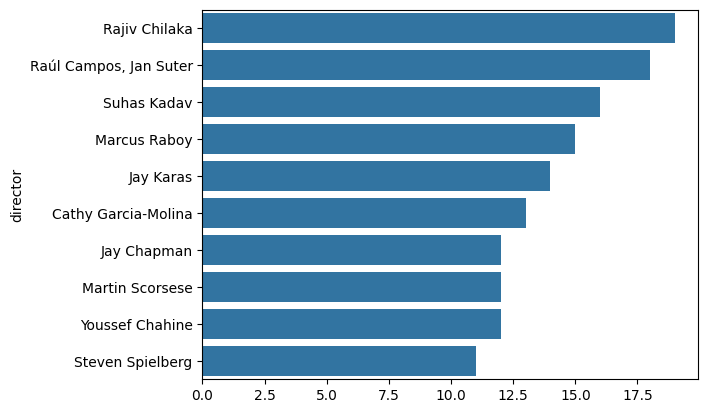

In [ ]:
# movie_director=df[df['type']=='Movie']
director_count=movie_director['director'].value_counts()[1:].head(10)
sns.barplot(x=director_counts.values,y=director_counts.index)

In [ ]:
cast=df['cast'].value_counts()
sns.barplot(x=cast.values,y=cast.index)


<Axes: ylabel='cast'>

/usr/local/lib/python3.12/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)


Error in callback <function _draw_all_if_interactive at 0x7a39401d5bc0> (for post_execute):


ValueError: 
Joey Bada$$, Andrew Howard, Zaria
         ^
ParseException: Expected end of text, found '$'  (at char 9), (line:1, col:10)

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


ValueError: 
Joey Bada$$, Andrew Howard, Zaria
         ^
ParseException: Expected end of text, found '$'  (at char 9), (line:1, col:10)

<Figure size 640x480 with 1 Axes>

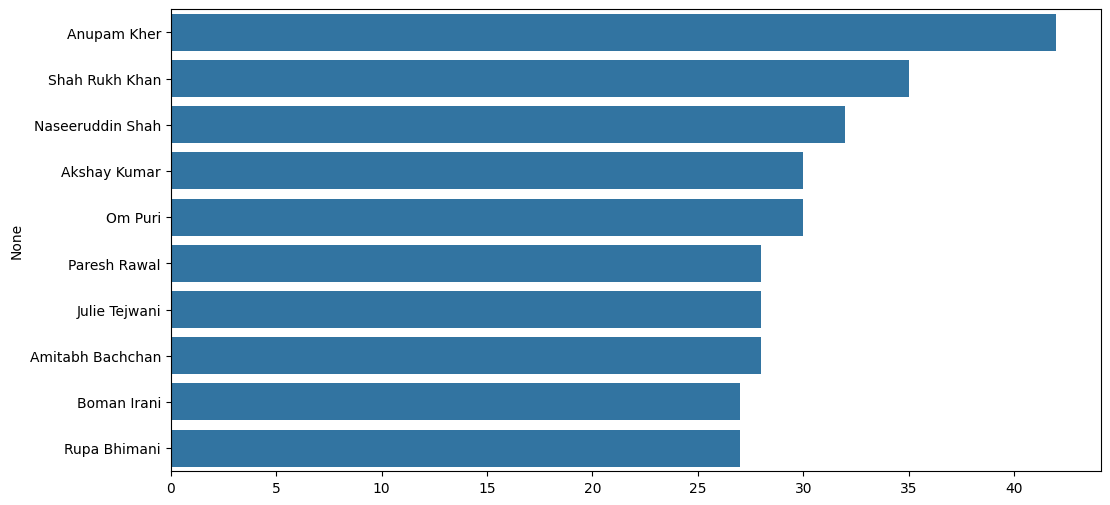

In [ ]:
movies_df = df[df['type'] == 'Movie'].copy()

all_movie_casts = []
for index, row in movies_df.iterrows():
    if row['cast'] != 'Unknown' and row['cast'] != '':
        cast_members = [c.strip() for c in row['cast'].split(',')]
        all_movie_casts.extend(cast_members)

# Count the occurrences of each cast member
cast_contribution = pd.Series(all_movie_casts).value_counts().head(10)

# Plotting the bar graph
plt.figure(figsize=(12, 6))
sns.barplot(x=cast_contribution.values, y=cast_contribution.index)

plt.show()

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'United States'),
  Text(1, 0, 'India'),
  Text(2, 0, 'United Kingdom'),
  Text(3, 0, 'Japan'),
  Text(4, 0, 'South Korea'),
  Text(5, 0, 'Canada'),
  Text(6, 0, 'Spain'),
  Text(7, 0, 'France'),
  Text(8, 0, 'Mexico'),
  Text(9, 0, 'Egypt')])

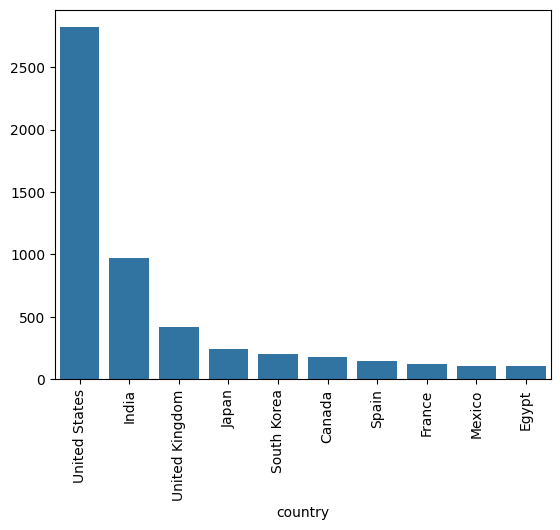

In [ ]:
removed_unknown=df[df['country']!='Unknown']
sns.barplot(x=removed_unknown['country'].value_counts().head(10).index,y=removed_unknown['country'].value_counts().head(10).values)
# sns.countplot(x='removed_unknown',data=df,order=df['removed_unk'].value_counts().head(10).index)
#.drop too
plt.xticks(rotation=90)


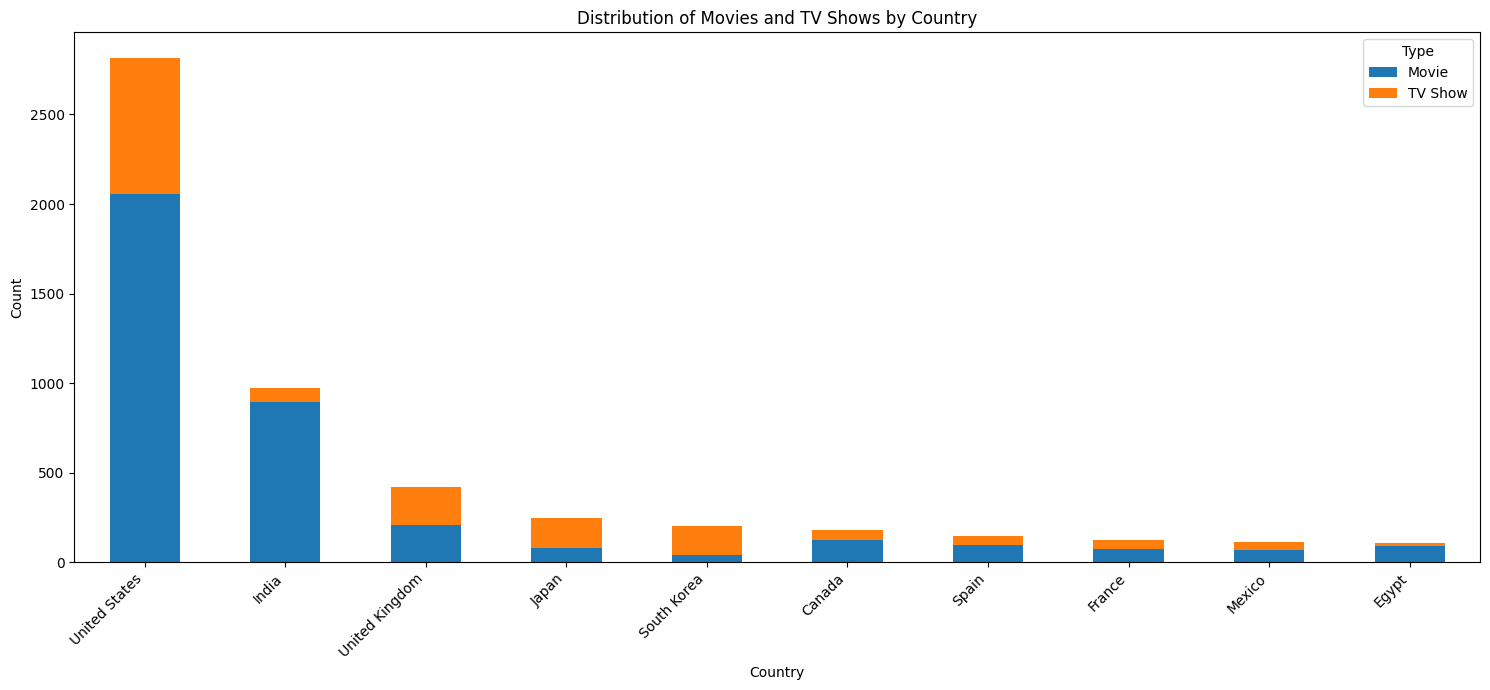

In [ ]:
country_type_distribution = df[df['country'] != 'Unknown'].groupby(['country', 'type']).size().unstack(fill_value=0)

top_countries = df['country'].value_counts().drop('Unknown', errors='ignore').head(10).index
country_type_distribution_top = country_type_distribution.loc[top_countries]

country_type_distribution_top.plot(kind='bar', figsize=(15, 7), stacked=True)
plt.title('Distribution of Movies and TV Shows by Country')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Type')
plt.tight_layout()
plt.show()

In [ ]:
country_type_distribution_long = country_type_distribution_top.reset_index().melt(id_vars='country', var_name='type', value_name='count')

plt.figure(figsize=(15, 7))
sns.barplot(x='country', y='count', hue='type', data=country_type_distribution_long, palette='viridis')
plt.title('Distribution of Movies and TV Shows by Country (Seaborn)')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Type')
plt.tight_layout()
plt.show()

In [ ]:
g = sns.catplot(
    data=country_type_distribution_long,
    x='country',
    y='count',
    hue='type',
    kind='bar',
    height=6,
    aspect=2,
    palette='deep'
)
g.set_axis_labels("Country", "Count")
g.set_xticklabels(rotation=45, ha='right')
g.set_xlabels("Country")
g.set_ylabels("Count")
plt.title('Distribution of Movies and TV Shows by Country (Seaborn Catplot)')
plt.tight_layout()
plt.show()

In [ ]:
country_type_counts = df[df['country'] != 'Unknown'].groupby(['country', 'type']).size()

# Get top countries similar to previous examples for consistency
top_countries = df['country'].value_counts().drop('Unknown', errors='ignore').head(10).index

# Filter the grouped series to include only top countries
country_type_counts_top = country_type_counts.loc[top_countries]

# Plotting directly from the grouped Series
plt.figure(figsize=(15, 7))
country_type_counts_top.unstack().plot(kind='bar', figsize=(15, 7))
plt.title('Distribution of Movies and TV Shows by Country (Groupby and Pandas Plot)')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Type')
plt.tight_layout()
plt.show()